In [ ]:
import os, glob, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
TRAIN_END_YEAR = 2015

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

## 2. Load the CSV file

In [ ]:
# Search for a CSV directly, or extract the first CSV found inside a ZIP file.
csv_candidates = glob.glob("*.csv") + glob.glob("/content/**/*.csv", recursive=True)
zip_candidates = glob.glob("*.zip") + glob.glob("/content/**/*.zip", recursive=True)

if csv_candidates:
    csv_path = csv_candidates[0]
    df = pd.read_csv(csv_path)
    print("Loaded:", csv_path)
elif zip_candidates:
    zip_path = zip_candidates[0]
    with zipfile.ZipFile(zip_path) as z:
        csv_names = [n for n in z.namelist() if n.lower().endswith(".csv")]
        if not csv_names:
            raise FileNotFoundError("No CSV file found inside the ZIP archive.")
        with z.open(csv_names[0]) as f:
            df = pd.read_csv(f)
    print("Loaded", csv_names[0], "from", zip_path)
else:
    raise FileNotFoundError("Upload crop_yield.csv or its ZIP file to the notebook first.")

print("Shape:", df.shape)
display(df.head())
print("\\nColumns:", df.columns.tolist())

Loaded: crop_yield.csv
Shape: (19689, 10)


,Crop,Crop_Year,Season,State,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield
0,Arecanut,1997,Whole Year,Assam,73814.0,56708,2051.4,7024878.38,22882.34,0.796087
1,Arhar/Tur,1997,Kharif,Assam,6637.0,4685,2051.4,631643.29,2057.47,0.710435
2,Castor seed,1997,Kharif,Assam,796.0,22,2051.4,75755.32,246.76,0.238333
3,Coconut,1997,Whole Year,Assam,19656.0,126905000,2051.4,1870661.52,6093.36,5238.051739
4,Cotton(lint),1997,Kharif,Assam,1739.0,794,2051.4,165500.63,539.09,0.420909


\nColumns: ['Crop', 'Crop_Year', 'Season', 'State', 'Area', 'Production', 'Annual_Rainfall', 'Fertilizer', 'Pesticide', 'Yield']


## 3. Clean and inspect the data

In [ ]:
# Standardise column names and categorical text.
df.columns = df.columns.str.strip()
required = [
    "Crop", "Crop_Year", "Season", "State", "Area",
    "Annual_Rainfall", "Fertilizer", "Pesticide", "Yield"
]
missing_cols = [c for c in required if c not in df.columns]
if missing_cols:
    raise ValueError(f"Required columns missing from dataset: {missing_cols}")

for c in ["Crop", "Season", "State"]:
    df[c] = df[c].astype("string").str.strip()

for c in ["Crop_Year", "Area", "Annual_Rainfall", "Fertilizer", "Pesticide", "Yield"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

print("Missing values:")
display(df.isna().sum().to_frame("missing_count"))
print("Duplicate rows:", df.duplicated().sum())

# Remove exact duplicate rows and records without a usable target/year.
df = df.drop_duplicates()
df = df.dropna(subset=["Crop_Year", "Yield"])
df = df[df["Yield"] >= 0].copy()
df["Crop_Year"] = df["Crop_Year"].astype(int)

# Convert invalid negative input values to missing; the pipeline imputes them.
for c in ["Area", "Annual_Rainfall", "Fertilizer", "Pesticide"]:
    df.loc[df[c] < 0, c] = np.nan

print("Cleaned shape:", df.shape)
print("Year range:", df["Crop_Year"].min(), "to", df["Crop_Year"].max())
display(df.describe(include="all").T)

Missing values:


,missing_count
Crop,0
Crop_Year,0
Season,0
State,0
Area,0
Production,0
Annual_Rainfall,0
Fertilizer,0
Pesticide,0
Yield,0


Duplicate rows: 0
Cleaned shape: (19689, 10)
Year range: 1997 to 2020


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Crop,19689,55,Rice,1197,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Crop_Year,19689.0,NaN,NaN,NaN,2009.127584,6.498099,1997.0,2004.0,2010.0,2015.0,2020.0
Season,19689,6,Kharif,8232,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,19689,30,Karnataka,1432,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Area,19689.0,NaN,NaN,NaN,179926.570308,732828.675888,0.5,1390.0,9317.0,75112.0,50808100.0
Production,19689.0,NaN,NaN,NaN,16435941.273097,263056839.812567,0.0,1393.0,13804.0,122718.0,6326000000.0
Annual_Rainfall,19689.0,NaN,NaN,NaN,1437.755177,816.909589,301.3,940.7,1247.6,1643.7,6552.7
Fertilizer,19689.0,NaN,NaN,NaN,24103312.448806,94946004.482527,54.17,188014.62,1234957.44,10003847.2,4835406877.0
Pesticide,19689.0,NaN,NaN,NaN,48848.353392,213287.35486,0.09,356.7,2421.9,20041.7,15750511.0
Yield,19689.0,NaN,NaN,NaN,79.954009,878.306193,0.0,0.6,1.03,2.388889,21105.0


## 4. Exploratory data analysis

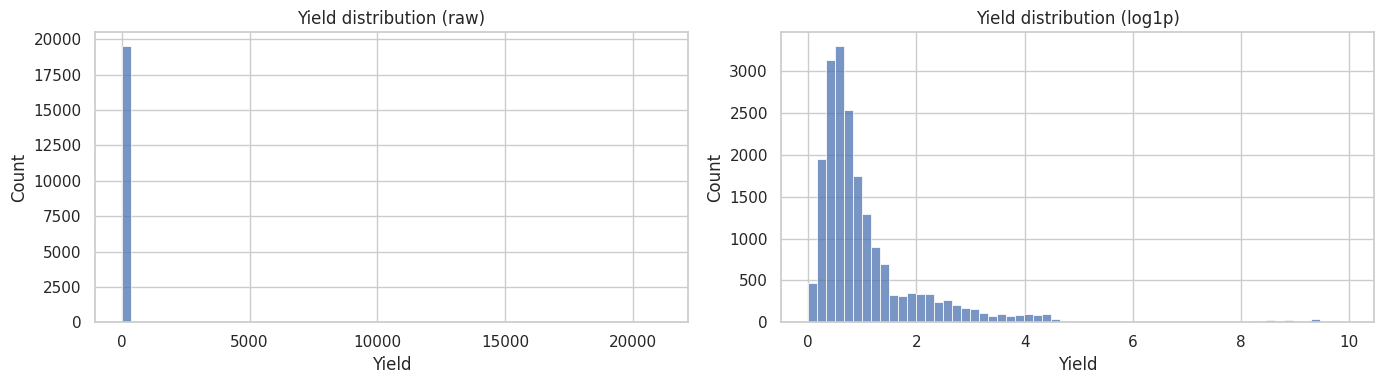

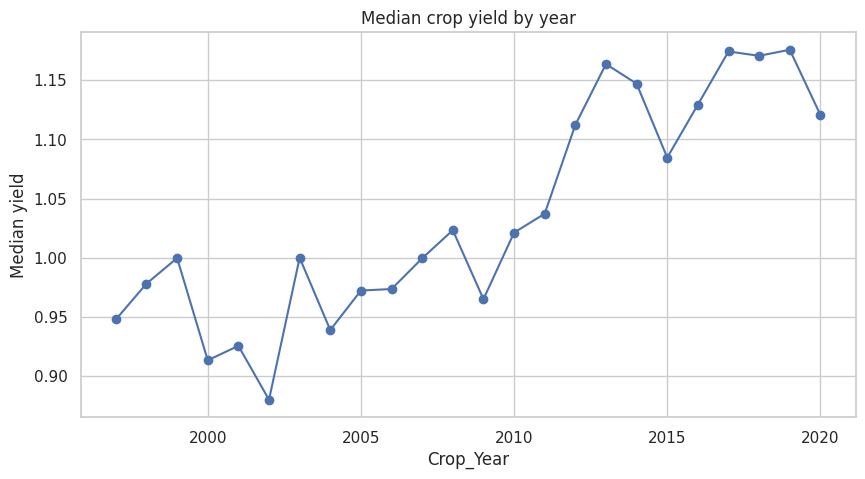

,count,mean,median
Season,,,
Whole Year,3717,412.995463,4.295122
Summer,1195,2.997370,1.673750
Winter,389,5.287267,1.545333
Autumn,414,3.917482,1.091677
Kharif,8232,2.482002,0.924226
Rabi,5742,1.988518,0.902660


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df["Yield"], bins=60, ax=axes[0])
axes[0].set_title("Yield distribution (raw)")
sns.histplot(np.log1p(df["Yield"]), bins=60, ax=axes[1])
axes[1].set_title("Yield distribution (log1p)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
yearly = df.groupby("Crop_Year")["Yield"].median()
yearly.plot(marker="o")
plt.title("Median crop yield by year")
plt.ylabel("Median yield")
plt.show()

display(df.groupby("Season")["Yield"].agg(["count", "mean", "median"]).sort_values("median", ascending=False))

## 5. Define the time-based train/test split

All records through 2015 are used for training. Records from 2016 onward are held out for testing. This is a more realistic test of forecasting into later years than a random split.

The features follow the research question: area, annual rainfall, fertiliser, pesticide, crop, season and state. `Production` and `Crop_Year` are not predictors.

In [ ]:
feature_cols = [
    "Area", "Annual_Rainfall", "Fertilizer", "Pesticide",
    "Crop", "Season", "State"
]
numeric_features = ["Area", "Annual_Rainfall", "Fertilizer", "Pesticide"]
categorical_features = ["Crop", "Season", "State"]

train_df = df[df["Crop_Year"] <= TRAIN_END_YEAR].copy()
test_df = df[df["Crop_Year"] > TRAIN_END_YEAR].copy()

if train_df.empty or test_df.empty:
    raise ValueError(
        f"Time split produced an empty set. Dataset years: "
        f"{df['Crop_Year'].min()}–{df['Crop_Year'].max()}. "
        "Adjust TRAIN_END_YEAR if needed."
    )

X_train, X_test = train_df[feature_cols], test_df[feature_cols]
y_train = np.log1p(train_df["Yield"].values)
y_test = test_df["Yield"].values

print(f"Train: {len(train_df):,} rows, years {train_df.Crop_Year.min()}–{train_df.Crop_Year.max()}")
print(f"Test : {len(test_df):,} rows, years {test_df.Crop_Year.min()}–{test_df.Crop_Year.max()}")

Train: 15,404 rows, years 1997–2015
Test : 4,285 rows, years 2016–2020


## 6. Preprocessing and outlier treatment

A quantile clipper learns the 1st and 99th percentile limits from the **training set only**, then applies those limits to both train and test data. This reduces the influence of extreme input values without allowing test data to influence preprocessing.

Numeric variables are median-imputed and standardised. Categorical variables are mode-imputed and one-hot encoded. Polynomial features are added only to numeric variables for the polynomial model.

In [ ]:
class QuantileClipper(BaseEstimator, TransformerMixin):
    def __init__(self, lower=0.01, upper=0.99):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.lower_bounds_ = np.nanquantile(X, self.lower, axis=0)
        self.upper_bounds_ = np.nanquantile(X, self.upper, axis=0)
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float)
        return np.clip(X, self.lower_bounds_, self.upper_bounds_)

numeric_preprocess = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("clipper", QuantileClipper(0.01, 0.99)),
    ("scaler", StandardScaler())
])

categorical_preprocess = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_preprocess, numeric_features),
    ("cat", categorical_preprocess, categorical_features)
])

# Polynomial expansion applies to numeric inputs only; categorical features remain one-hot encoded.
polynomial_preprocessor = ColumnTransformer(transformers=[
    ("num", Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("clipper", QuantileClipper(0.01, 0.99)),
        ("poly", PolynomialFeatures(degree=2, include_bias=False)),
        ("scaler", StandardScaler())
    ]), numeric_features),
    ("cat", categorical_preprocess, categorical_features)
])

## 7. Train and compare regression models

In [ ]:
models = {
    "Multiple Linear Regression": Pipeline([
        ("preprocess", preprocessor),
        ("model", LinearRegression())
    ]),
    "Polynomial Regression (degree 2)": Pipeline([
        ("preprocess", polynomial_preprocessor),
        ("model", LinearRegression())
    ]),
    "Ridge Regression": Pipeline([
        ("preprocess", preprocessor),
        ("model", Ridge(alpha=10.0))
    ]),
    "Lasso Regression": Pipeline([
        ("preprocess", preprocessor),
        ("model", Lasso(alpha=0.001, max_iter=20000))
    ]),
    "Decision Tree": Pipeline([
        ("preprocess", preprocessor),
        ("model", DecisionTreeRegressor(
            max_depth=12, min_samples_leaf=5, random_state=RANDOM_STATE
        ))
    ]),
    "k-NN Regressor": Pipeline([
        ("preprocess", preprocessor),
        ("model", KNeighborsRegressor(n_neighbors=10, weights="distance"))
    ])
}

results = []
fitted_models = {}
predictions = {}

for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    pred_log = pipe.predict(X_test)
    pred_yield = np.maximum(0, np.expm1(pred_log))
    predictions[name] = pred_yield
    fitted_models[name] = pipe

    rmse = np.sqrt(mean_squared_error(y_test, pred_yield))
    mae = mean_absolute_error(y_test, pred_yield)
    r2 = r2_score(y_test, pred_yield)
    results.append({"Model": name, "RMSE": rmse, "MAE": mae, "R2": r2})

results_df = pd.DataFrame(results).sort_values("RMSE")
display(results_df)

,Model,RMSE,MAE,R2
4,Decision Tree,182.894881,12.156815,0.953855
5,k-NN Regressor,191.795988,13.042113,0.949254
1,Polynomial Regression (degree 2),410.588042,30.469002,0.767439
0,Multiple Linear Regression,418.539727,31.775881,0.758344
3,Lasso Regression,461.265504,36.433283,0.706488
2,Ridge Regression,576.299345,47.319808,0.541837


## 8. Compare model performance

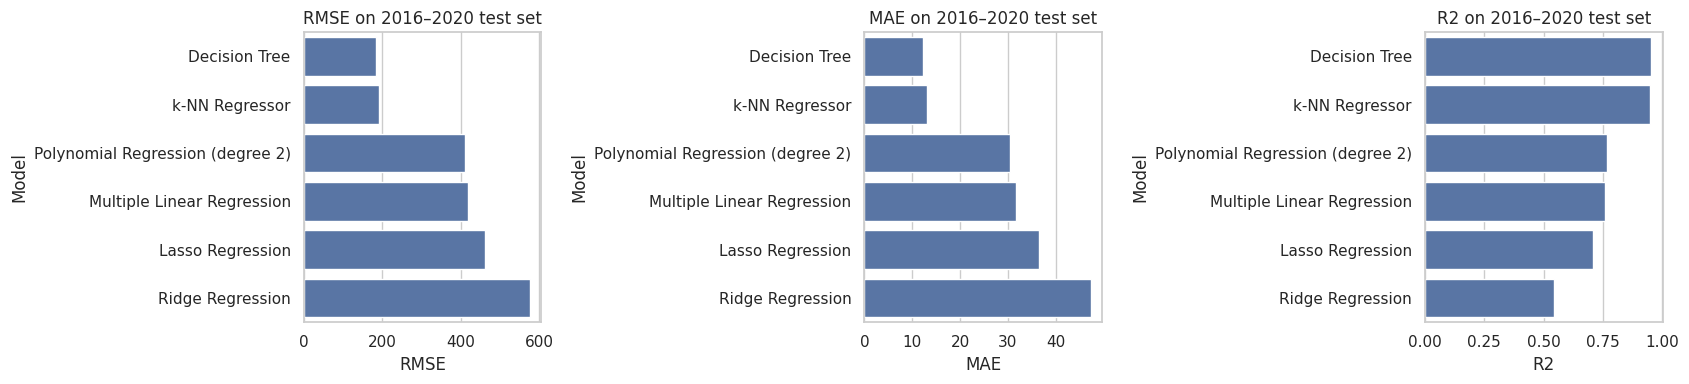

Best model by RMSE: Decision Tree


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for metric, ax in zip(["RMSE", "MAE", "R2"], axes):
    sns.barplot(data=results_df, x=metric, y="Model", ax=ax)
    ax.set_title(metric + " on 2016–2020 test set")
plt.tight_layout()
plt.show()

best_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_name]
best_pred = predictions[best_name]
print("Best model by RMSE:", best_name)

## 9. Actual vs predicted yield

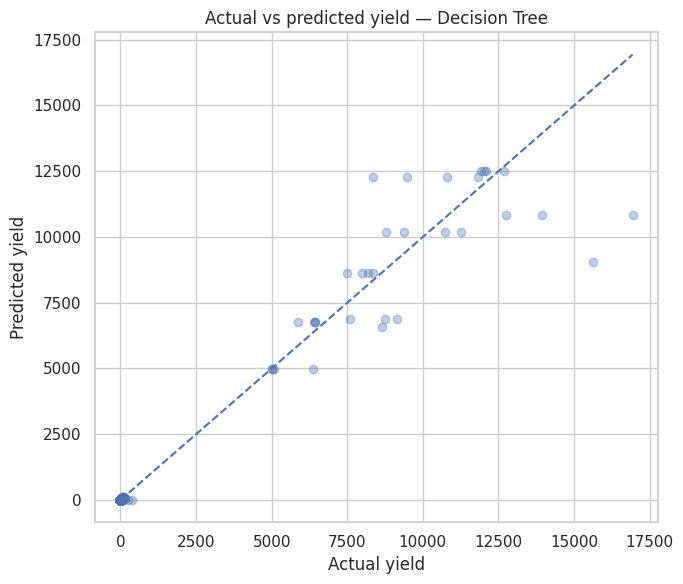

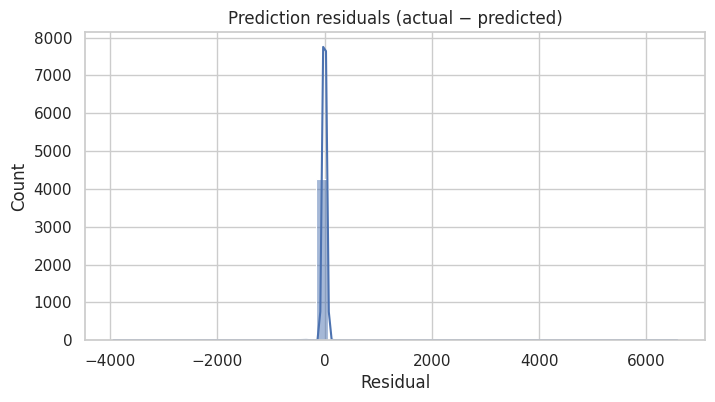

In [ ]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, best_pred, alpha=0.35)
max_val = max(np.nanmax(y_test), np.nanmax(best_pred))
plt.plot([0, max_val], [0, max_val], linestyle="--")
plt.xlabel("Actual yield")
plt.ylabel("Predicted yield")
plt.title(f"Actual vs predicted yield — {best_name}")
plt.tight_layout()
plt.show()

residuals = y_test - best_pred
plt.figure(figsize=(8, 4))
sns.histplot(residuals, bins=50, kde=True)
plt.title("Prediction residuals (actual − predicted)")
plt.xlabel("Residual")
plt.show()

## 10. Do higher fertiliser and pesticide inputs buy higher yield?

This section examines associations, not causal effects. Raw total input values can be misleading because larger cultivated areas tend to use more inputs. We therefore calculate input intensity per unit area and compare it with yield. The analysis is descriptive and does not establish that changing an input will cause yield to change.

,Yield,Fertilizer_per_area,Pesticide_per_area
Yield,1.000000,0.001844,-0.001594
Fertilizer_per_area,0.001844,1.000000,0.387212
Pesticide_per_area,-0.001594,0.387212,1.000000


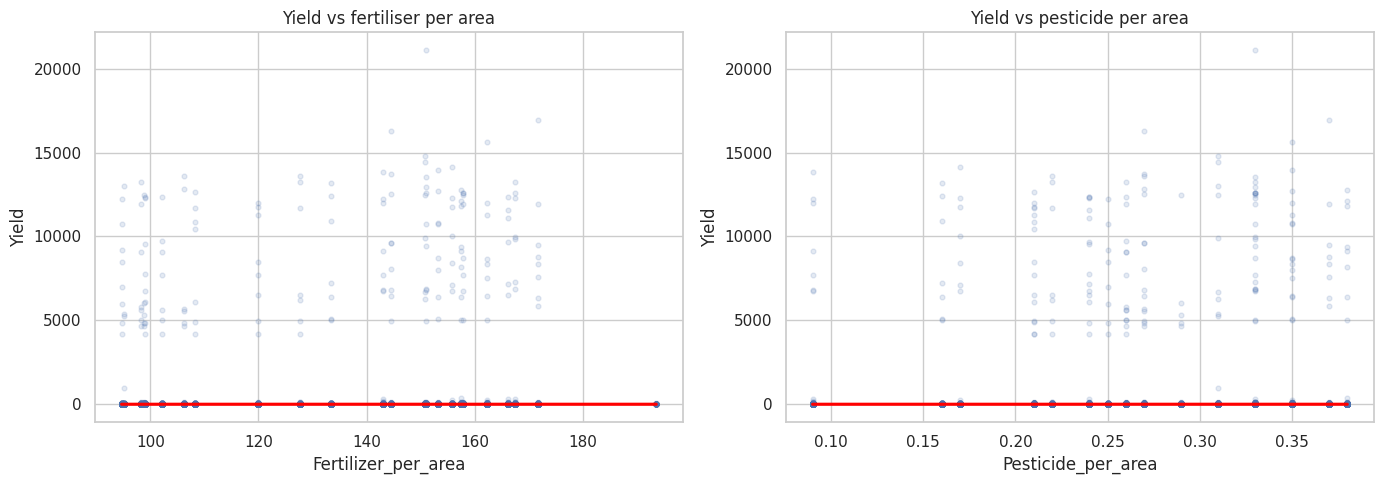

\n Fertilizer_per_area


,count,mean,median
Fertilizer_per_area_group,,,
Q1 (lowest),3938,74.783103,0.941535
Q2,3938,81.526799,0.973452
Q3,3937,90.649845,1.101818
Q4,3938,77.006540,1.080000
Q5 (highest),3938,75.806474,1.100455


\n Pesticide_per_area


,count,mean,median
Pesticide_per_area_group,,,
Q1 (lowest),3938,84.791778,0.983595
Q2,3938,89.490608,0.984969
Q3,3937,69.855601,1.000000
Q4,3938,90.370721,1.101073
Q5 (highest),3938,65.258773,1.140909


In [ ]:
eff = df.copy()
eff = eff[(eff["Area"] > 0) & eff["Yield"].notna()].copy()
eff["Fertilizer_per_area"] = eff["Fertilizer"] / eff["Area"]
eff["Pesticide_per_area"] = eff["Pesticide"] / eff["Area"]

display(eff[["Yield", "Fertilizer_per_area", "Pesticide_per_area"]].corr())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.regplot(data=eff, x="Fertilizer_per_area", y="Yield",
            scatter_kws={"alpha": 0.15, "s": 12}, line_kws={"color": "red"},
            ax=axes[0], lowess=True)
axes[0].set_title("Yield vs fertiliser per area")
sns.regplot(data=eff, x="Pesticide_per_area", y="Yield",
            scatter_kws={"alpha": 0.15, "s": 12}, line_kws={"color": "red"},
            ax=axes[1], lowess=True)
axes[1].set_title("Yield vs pesticide per area")
plt.tight_layout()
plt.show()

# Summarise input intensity and yield by intensity quintile.
for input_col in ["Fertilizer_per_area", "Pesticide_per_area"]:
    eff[input_col + "_group"] = pd.qcut(
        eff[input_col].rank(method="first"), 5,
        labels=["Q1 (lowest)", "Q2", "Q3", "Q4", "Q5 (highest)"]
    )
    summary = eff.groupby(input_col + "_group", observed=False)["Yield"].agg(
        ["count", "mean", "median"]
    )
    print("\\n", input_col)
    display(summary)

## 11. State-level input-use efficiency patterns

A simple descriptive indicator is median yield divided by median input intensity. It is not a complete agronomic efficiency measure and should not be interpreted causally. The table helps identify states for further investigation.

,records,median_yield,median_fertiliser_per_area,median_pesticide_per_area
State,,,,
Delhi,203,2.590000,133.40,0.26
Goa,246,2.030000,144.49,0.27
Puducherry,670,1.935000,150.96,0.27
Kerala,534,1.700000,144.49,0.27
Arunachal Pradesh,292,1.516883,150.88,0.31
Meghalaya,649,1.490000,144.49,0.27
Tamil Nadu,822,1.487136,150.80,0.27
Mizoram,416,1.326250,144.49,0.27
Telangana,397,1.315000,157.44,0.35


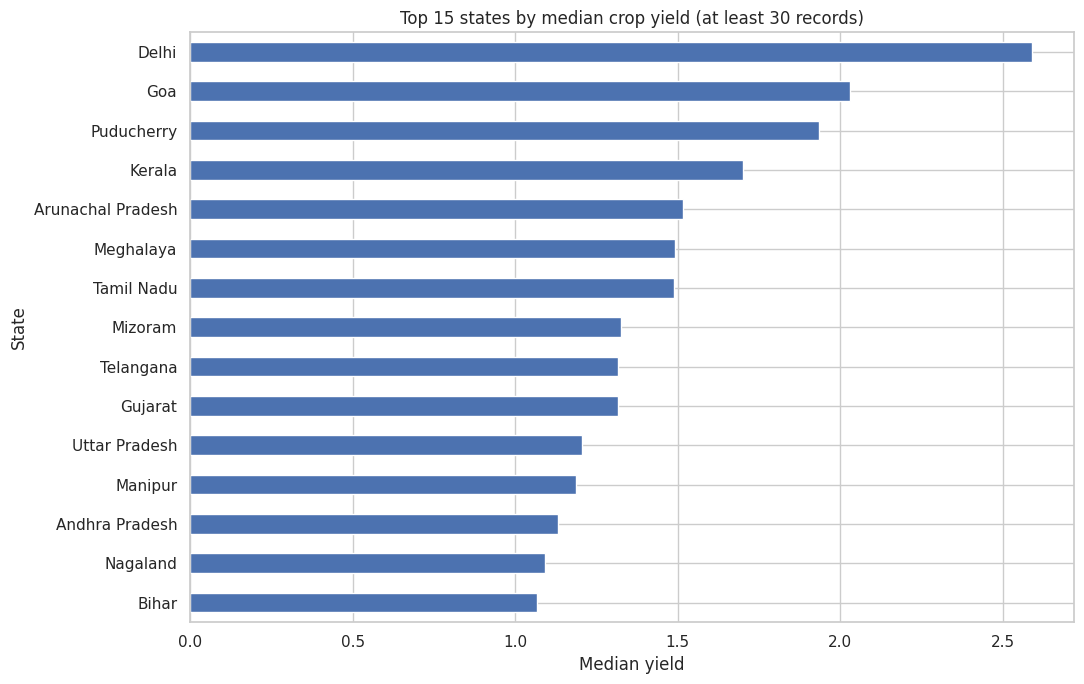

In [ ]:
state_efficiency = (
    eff.groupby("State")
       .agg(
           records=("Yield", "size"),
           median_yield=("Yield", "median"),
           median_fertiliser_per_area=("Fertilizer_per_area", "median"),
           median_pesticide_per_area=("Pesticide_per_area", "median")
       )
       .query("records >= 30")
       .sort_values("median_yield", ascending=False)
)
display(state_efficiency.head(20))

fig, ax = plt.subplots(figsize=(11, 7))
top_states = state_efficiency.head(15).sort_values("median_yield")
top_states["median_yield"].plot(kind="barh", ax=ax)
ax.set_title("Top 15 states by median crop yield (at least 30 records)")
ax.set_xlabel("Median yield")
plt.tight_layout()
plt.show()

## 12. Permutation feature importance

Permutation importance estimates how much test-set performance worsens when a feature is shuffled. This is calculated on the best model using the held-out years. Because the model uses a preprocessing pipeline, importance is computed on the original input columns.

,Feature,Importance_mean,Importance_std
4,Crop,0.443078,0.012084
1,Annual_Rainfall,0.008382,0.001407
3,Pesticide,0.008284,0.002092
0,Area,0.003999,0.001855
6,State,0.003352,0.001628
2,Fertilizer,0.000229,0.001719
5,Season,0.000069,0.000346


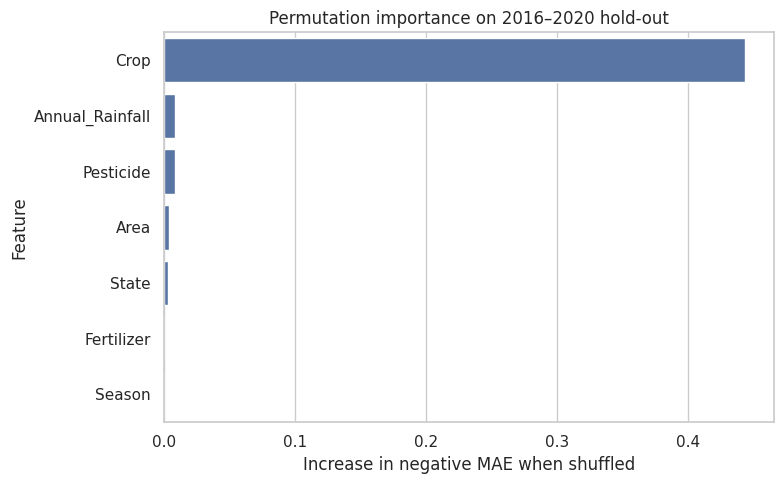

In [ ]:
perm = permutation_importance(
    best_model, X_test, y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
importance_df = pd.DataFrame({
    "Feature": feature_cols,
    "Importance_mean": perm.importances_mean,
    "Importance_std": perm.importances_std
}).sort_values("Importance_mean", ascending=False)

display(importance_df)
plt.figure(figsize=(8, 5))
sns.barplot(data=importance_df, x="Importance_mean", y="Feature")
plt.title("Permutation importance on 2016–2020 hold-out")
plt.xlabel("Increase in negative MAE when shuffled")
plt.tight_layout()
plt.show()

## 13. Save predictions and model comparison

In [ ]:
prediction_output = test_df[["Crop_Year", "Crop", "Season", "State", "Yield"]].copy()
prediction_output["Predicted_Yield"] = best_pred
prediction_output["Absolute_Error"] = np.abs(
    prediction_output["Yield"] - prediction_output["Predicted_Yield"]
)
prediction_output.to_csv("crop_yield_test_predictions.csv", index=False)
results_df.to_csv("crop_yield_model_comparison.csv", index=False)

print("Saved:")
print("- crop_yield_test_predictions.csv")
print("- crop_yield_model_comparison.csv")
display(prediction_output.head())

Saved:
- crop_yield_test_predictions.csv
- crop_yield_model_comparison.csv


,Crop_Year,Crop,Season,State,Yield,Predicted_Yield,Absolute_Error
4733,2016,Arecanut,Kharif,Andhra Pradesh,3.912500,0.896815,3.015685
4734,2016,Arhar/Tur,Kharif,Andhra Pradesh,0.493077,0.896815,0.403738
4735,2016,Arhar/Tur,Rabi,Andhra Pradesh,0.481818,0.896815,0.414997
4736,2016,Bajra,Kharif,Andhra Pradesh,1.744545,0.896815,0.847731
4737,2016,Bajra,Rabi,Andhra Pradesh,1.827143,0.896815,0.930328
